# Experiment 1 - No Grokking

## MNIST Data

In [1]:
import pandas as pd

mnist_train = pd.read_csv("mnist_train.csv", header=None)
mnist_test = pd.read_csv("mnist_test.csv", header=None)

mnist = pd.concat([mnist_train, mnist_test], ignore_index=True)

X_train = mnist_train.loc[:, mnist_train.columns[1:]].to_numpy()
y_train = mnist_train.loc[:, mnist_train.columns[0]].to_numpy()

X_test = mnist_test.loc[:, mnist_test.columns[1:]].to_numpy()
y_test = mnist_test.loc[:, mnist_test.columns[0]].to_numpy()

In [2]:
mnist

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


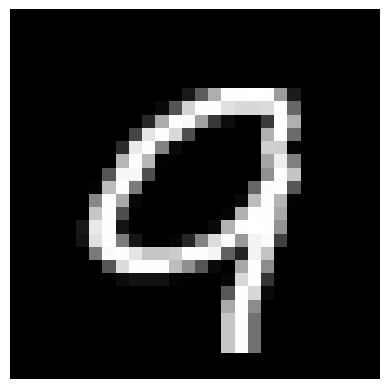

<Figure size 640x480 with 0 Axes>

In [3]:
from utils import display_digit

display_digit(mnist, 3000)

## Neural Network Class

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
from tqdm import tqdm


class MNISTClassifier:

    def __init__(self, model, lr=0.01, epochs=20, batch_size=32):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.model = model.to(self.device)
        self.train_losses = []
        self.val_losses = []
        
    def fit(self, X, y, val_perc=10, show_progress=False):
        num_rows = int(X.shape[0] * (val_perc / 100))
        
        # Prepare Train Dataset
        self.train_losses = []
        
        X_train = X[:-num_rows]
        y_train = y[:-num_rows]

        X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
        y_train_tensor = torch.tensor(y_train)

        train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
        train_dataloader = DataLoader(train_dataset, batch_size=self.batch_size, shuffle=True)

        # Prepare Validation Dataset
        self.val_losses = []
        
        X_val = X[-num_rows:]
        y_val = y[-num_rows:]

        X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
        y_val_tensor = torch.tensor(y_val)

        val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
        val_dataloader = DataLoader(val_dataset, batch_size=self.batch_size, shuffle=True)

        # Define Criterion and Optimizer
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.model.parameters(), lr=self.lr)
        
        for epoch in tqdm(range(self.epochs), disable=(not show_progress)):
            # Training Phase ------------------------------------------------------
            self.model.train()
            
            train_batch_losses = []
            for batch_X, batch_y in train_dataloader:
                batch_X, batch_y = batch_X.to(self.device), batch_y.to(self.device)
                optimizer.zero_grad()
                
                outputs = self.model(batch_X)
                loss = criterion(outputs, batch_y)

                train_batch_loss = loss.item()
                train_batch_losses.append(train_batch_loss)
                
                loss.backward()
                optimizer.step()

            train_avg_loss = sum(train_batch_losses) / len(train_batch_losses)
            self.train_losses.append(train_avg_loss)

            #Validation Phase ------------------------------------------------------
            self.model.eval()

            val_batch_losses = []
            with torch.no_grad():
                for batch_X, batch_y in val_dataloader:
                    batch_X, batch_y = batch_X.to(self.device), batch_y.to(self.device)
                    
                    outputs = self.model(batch_X)
                    loss = criterion(outputs, batch_y)
                
                    val_batch_loss = loss.item()
                    val_batch_losses.append(val_batch_loss)

            val_avg_loss = sum(val_batch_losses) / len(val_batch_losses)
            self.val_losses.append(val_avg_loss)
                
        return self

    def predict_proba(self, X):
        if self.model is None:
            raise RuntimeError("The model must be fitted before predicting.")
            
        self.model.eval()
        X_tensor = torch.tensor(X, dtype=torch.float32).to(self.device)
        
        with torch.no_grad():
            logits = self.model(X_tensor)
            probabilities = torch.softmax(logits, dim=1).cpu().numpy()
            
        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)
        
        return np.argmax(probabilities, axis=1)

## Model Architecture

In [5]:
import torch.nn as nn

class Model(nn.Module):

    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(28 * 28, 128), nn.ReLU(), nn.Linear(128, 10))
        
    def forward(self, x):
        return self.network(x)

## MNIST Classifier - 5 epochs

### Training

In [6]:
#from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=5, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


### Evaluation

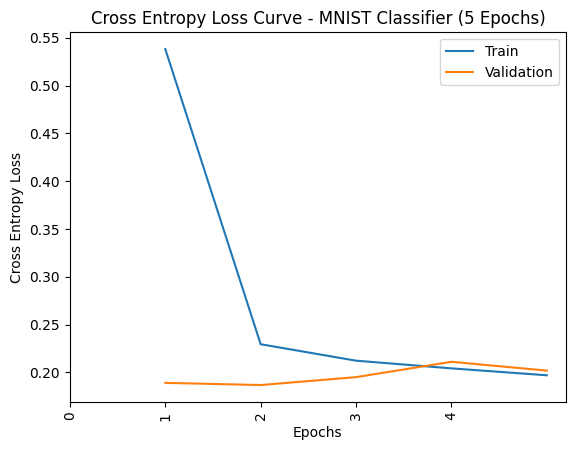

<Figure size 640x480 with 0 Axes>

In [7]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses, title='Cross Entropy Loss Curve - MNIST Classifier (5 Epochs)')

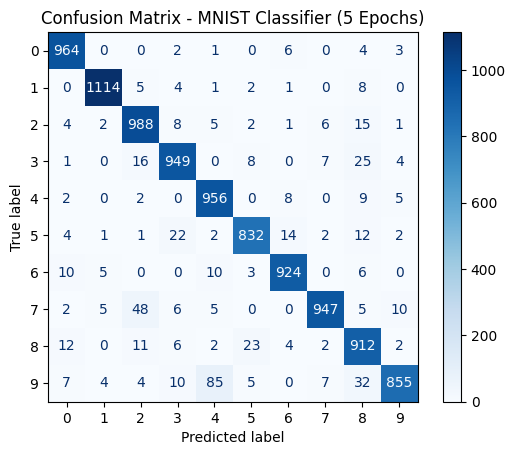

<Figure size 640x480 with 0 Axes>

In [8]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred, title='Confusion Matrix - MNIST Classifier (5 Epochs)')

In [9]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.9535333333333333
Test Accuracy:  0.9441


Layer: network.0.weight | Shape: torch.Size([128, 784])


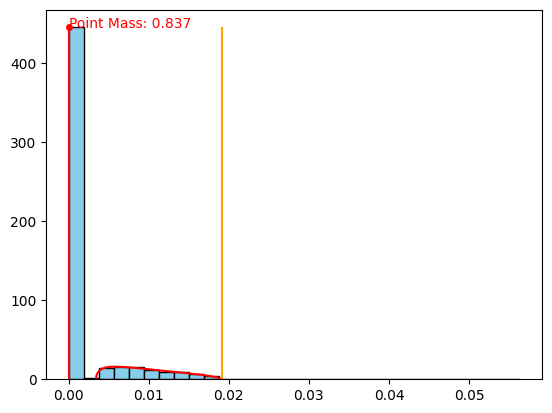

Layer: network.2.weight | Shape: torch.Size([10, 128])


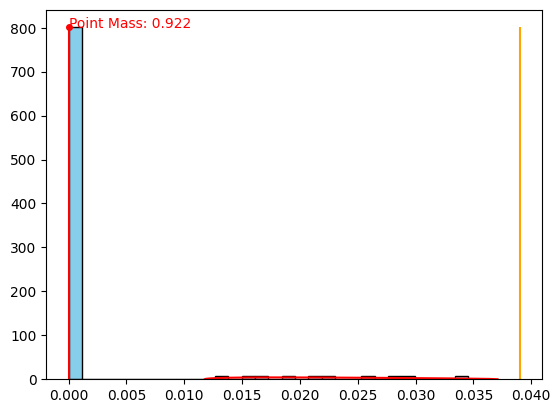

<Figure size 640x480 with 0 Axes>

In [10]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)

## MNIST Classifier - 100 epochs

### Training

In [11]:
from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=100, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


### Evaluation

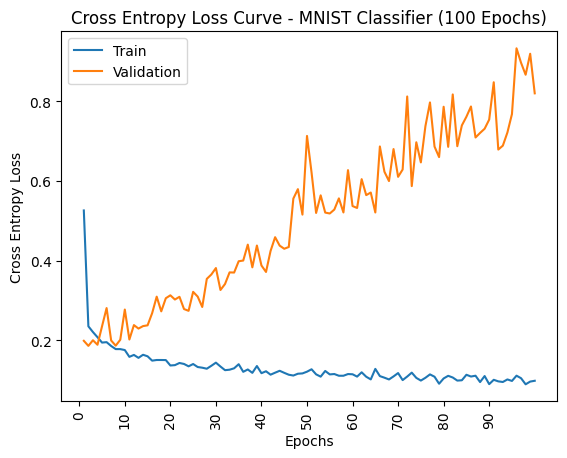

<Figure size 640x480 with 0 Axes>

In [12]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses, title='Cross Entropy Loss Curve - MNIST Classifier (100 Epochs)')

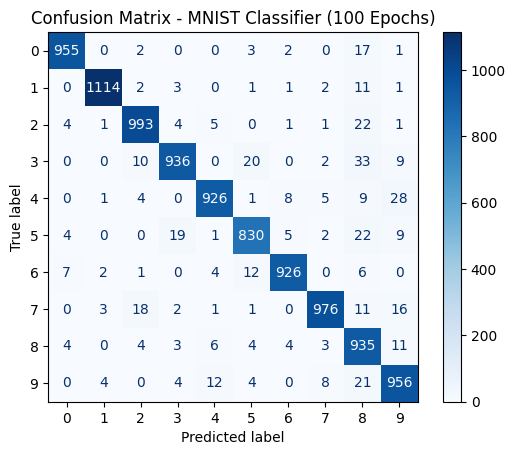

<Figure size 640x480 with 0 Axes>

In [13]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred, 'Confusion Matrix - MNIST Classifier (100 Epochs)')

In [14]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.98275
Test Accuracy:  0.9547


Layer: network.0.weight | Shape: torch.Size([128, 784])


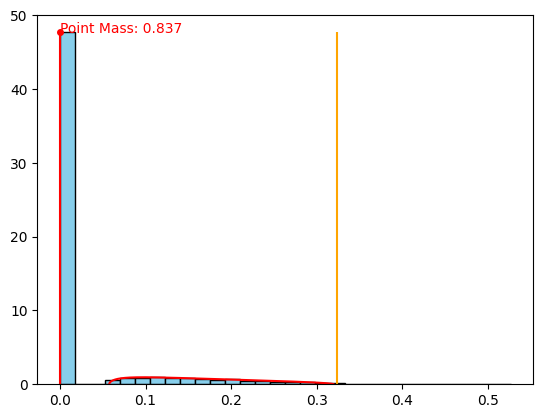

Layer: network.2.weight | Shape: torch.Size([10, 128])


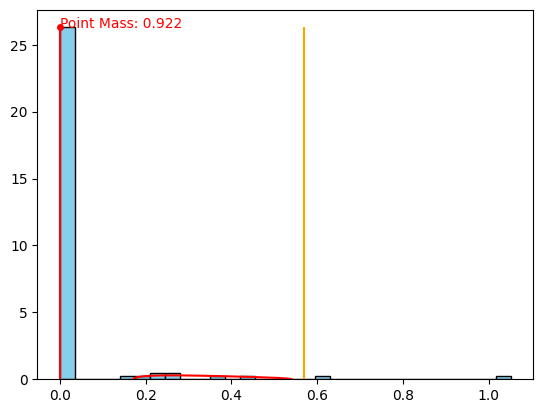

<Figure size 640x480 with 0 Axes>

In [15]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)

## MNIST Classifier - 200 epochs

### Training

In [16]:
from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=200, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


### Evaluation

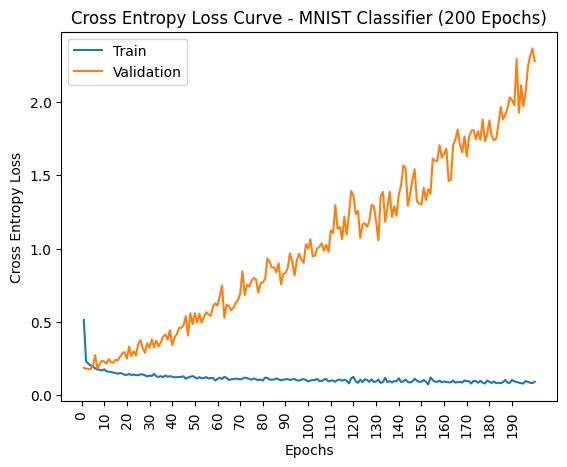

<Figure size 640x480 with 0 Axes>

In [17]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses, title='Cross Entropy Loss Curve - MNIST Classifier (200 Epochs)')

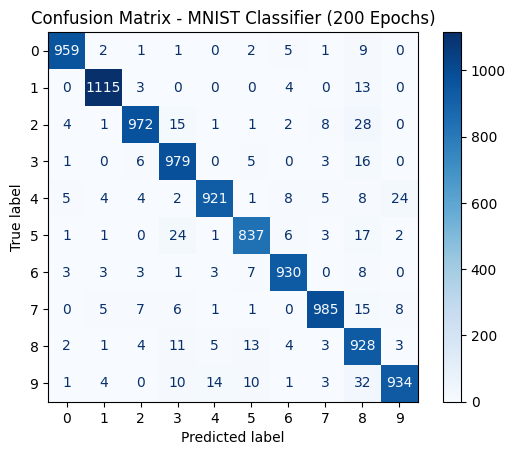

<Figure size 640x480 with 0 Axes>

In [18]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred, title='Confusion Matrix - MNIST Classifier (200 Epochs)')

In [19]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.9830666666666666
Test Accuracy:  0.956


Layer: network.0.weight | Shape: torch.Size([128, 784])


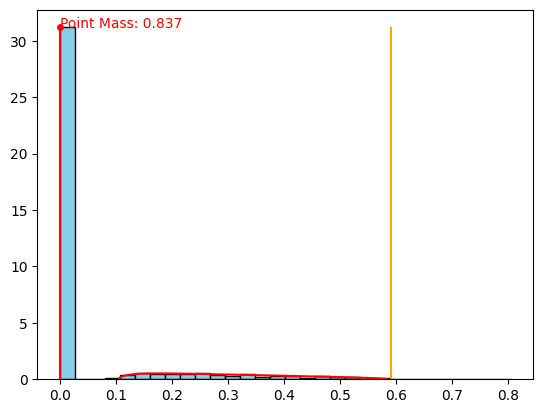

Layer: network.2.weight | Shape: torch.Size([10, 128])


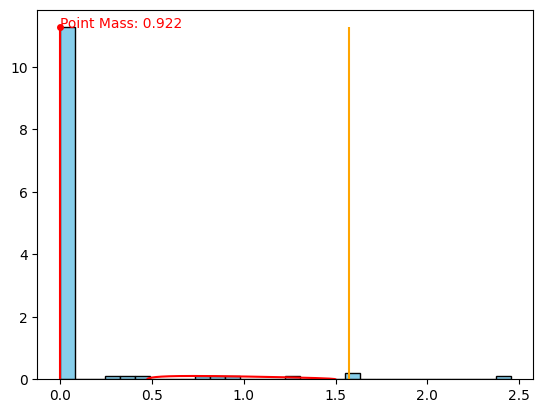

<Figure size 640x480 with 0 Axes>

In [20]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)

## MNIST Classifier - 300 epochs

### Training

In [21]:
from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=300, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


### Evaluation

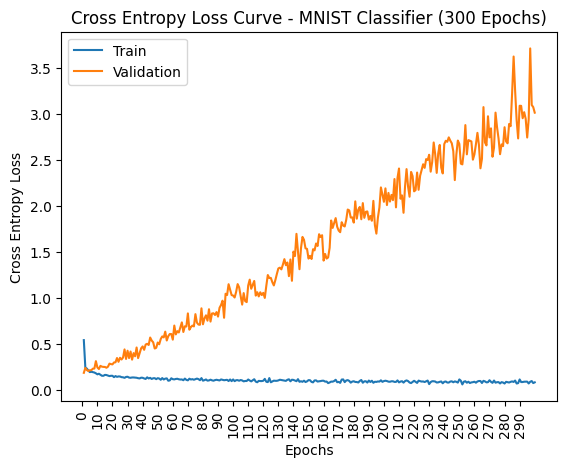

<Figure size 640x480 with 0 Axes>

In [22]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses, title='Cross Entropy Loss Curve - MNIST Classifier (300 Epochs)')

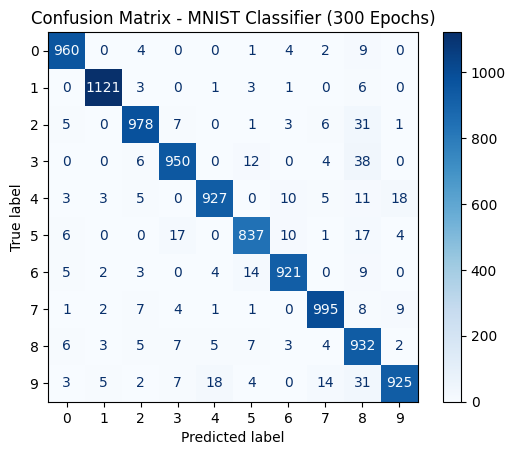

<Figure size 640x480 with 0 Axes>

In [23]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred, title='Confusion Matrix - MNIST Classifier (300 Epochs)')

In [24]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.9839166666666667
Test Accuracy:  0.9546


Layer: network.0.weight | Shape: torch.Size([128, 784])


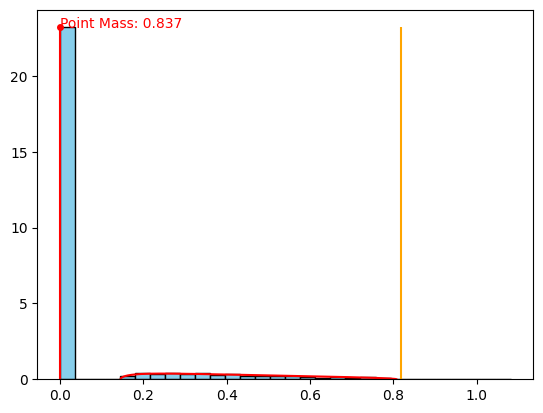

Layer: network.2.weight | Shape: torch.Size([10, 128])


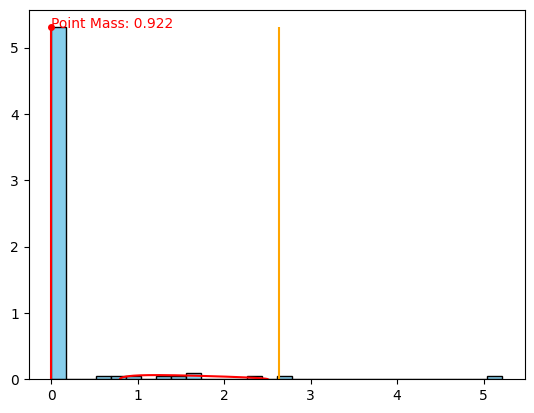

<Figure size 640x480 with 0 Axes>

In [25]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)

## MNIST Classifier - 1000 epochs

### Training

In [26]:
from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=1000, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


### Evaluation

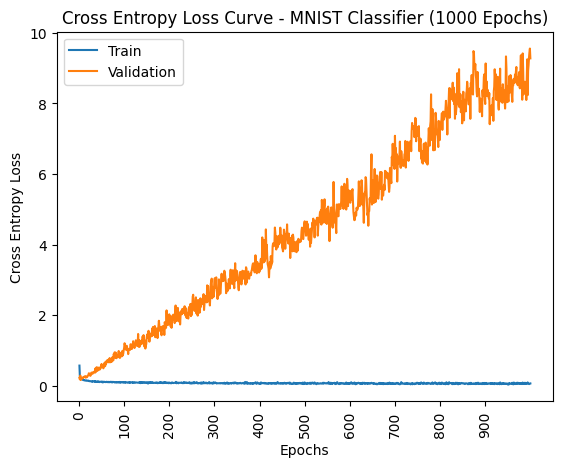

<Figure size 640x480 with 0 Axes>

In [27]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses,  title='Cross Entropy Loss Curve - MNIST Classifier (1000 Epochs)')

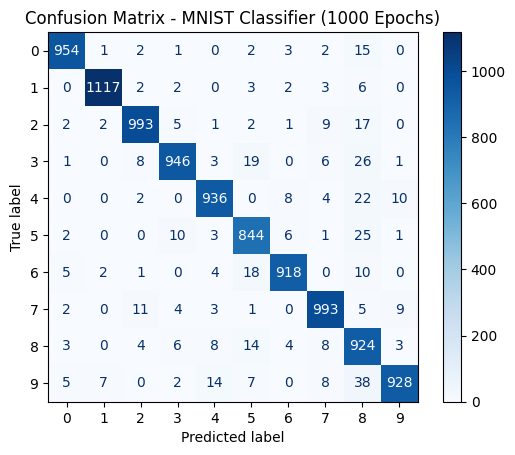

<Figure size 640x480 with 0 Axes>

In [28]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred, title='Confusion Matrix - MNIST Classifier (1000 Epochs)')

In [29]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.9845833333333334
Test Accuracy:  0.9553


Layer: network.0.weight | Shape: torch.Size([128, 784])


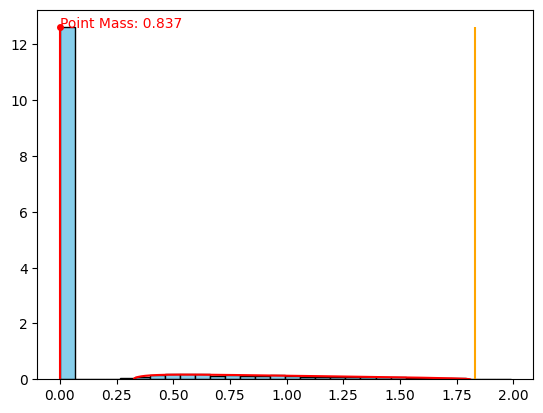

Layer: network.2.weight | Shape: torch.Size([10, 128])


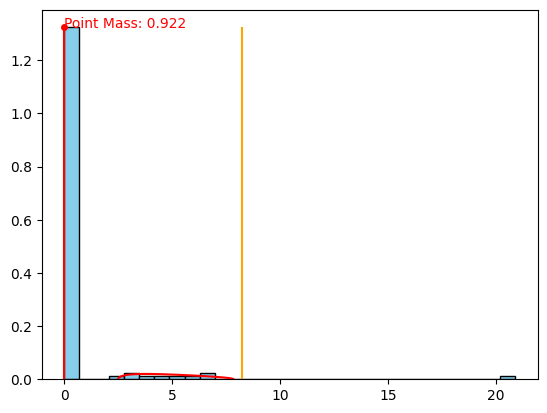

<Figure size 640x480 with 0 Axes>

In [30]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)

## MNIST Classifier - 2000 epochs

### Training

In [31]:
from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=2000, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


### Evaluation

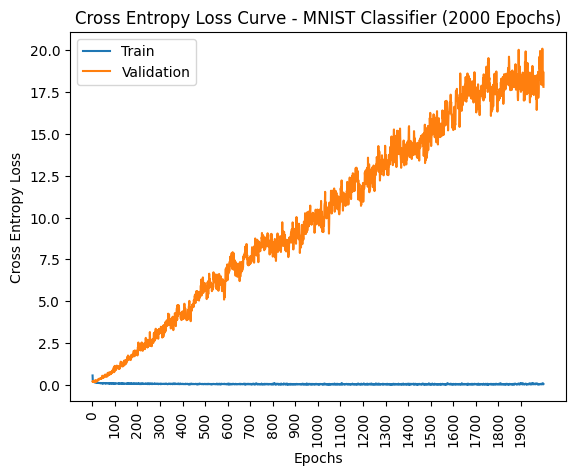

<Figure size 640x480 with 0 Axes>

In [32]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses, title='Cross Entropy Loss Curve - MNIST Classifier (2000 Epochs)')

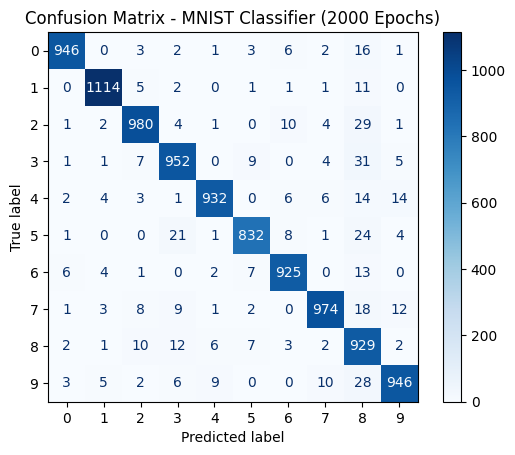

<Figure size 640x480 with 0 Axes>

In [33]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred, title='Confusion Matrix - MNIST Classifier (2000 Epochs)')

In [34]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.9846333333333334
Test Accuracy:  0.953


Layer: network.0.weight | Shape: torch.Size([128, 784])


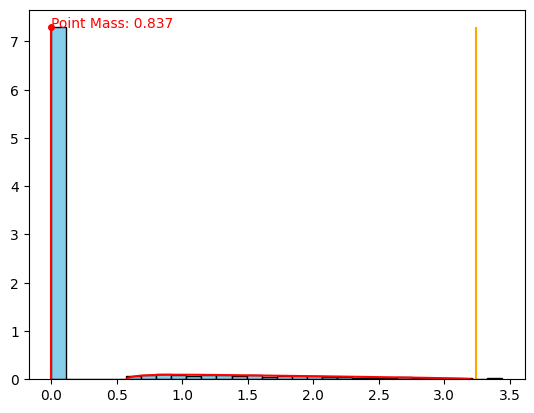

Layer: network.2.weight | Shape: torch.Size([10, 128])


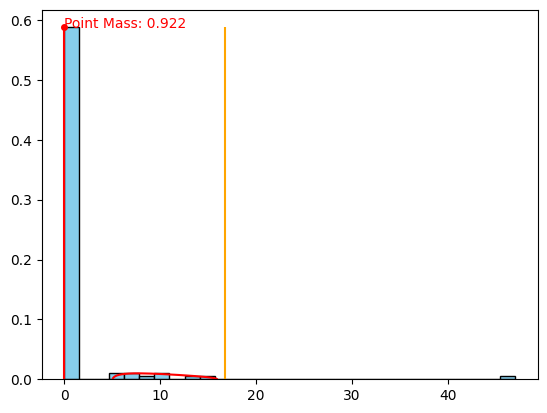

<Figure size 640x480 with 0 Axes>

In [35]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)